> STATUS: ATUAL — execução final SEM, BEST época 2.
> Revisão editorial em 30/10/2026: somente apresentação de resultados existentes; este notebook não foi reexecutado nesta revisão.
> Consulte o [guia oficial](../../../GUIA_NOTEBOOKS_RESULTADOS.md). Os notebooks 03/04 contêm chamadas de inferência; seus outputs estão preservados e não devem ser reexecutados nesta etapa editorial.


# 02 — Exploração do LUDB (conjunto de teste)

Verificação do dataset gerado por `src/preprocess_ludb.py`, com foco nas
regiões clínicas delimitadas pelos especialistas (ondas P, T e complexo QRS) —
o *ground truth* espacial contra o qual os mapas do Grad-CAM serão medidos.

Os artefatos desta execução já estão presentes no pacote. Não é necessário executar o pipeline para consultar estes outputs; veja o guia oficial.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

# O codigo do projeto vive em src/ (nao ha pacote instalavel).
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
import beat_io

dados = beat_io.load_beat_dataset(config.LUDB_PROCESSED_FILE)

X = dados["series"]
y = dados["labels"]
simbolos = dados["simbolos"]
pacientes = dados["pacientes"]
tem_onda_p = dados["tem_onda_p"].astype(bool)

print(f"series    : {X.shape} {X.dtype}")
print(f"labels    : {np.bincount(y)} (0 = referência negativa, 1 = alvo compartilhado)")
print(f"pacientes : {len(np.unique(pacientes))} registros")

series    : (192, 234) float32
labels    : [107  85] (0 = referência negativa, 1 = alvo compartilhado)
pacientes : 28 registros


## 1. Distribuição por ritmo

O LUDB diagnostica o **registro**, não o batimento. `Rhythm` é propagado como
metadado para análise, mas não determina o label das políticas compartilhadas.

In [2]:
ritmos, contagens = np.unique(simbolos, return_counts=True)
ordem = np.argsort(-contagens)

print(f"{'ritmo':<28} {'classe 0':>8} {'classe 1':>8} {'pacientes':>10} {'com P':>7}")
for i in ordem:
    ritmo = ritmos[i]
    seletor = simbolos == ritmo
    n0, n1 = int((y[seletor] == 0).sum()), int((y[seletor] == 1).sum())
    n_pacientes = len(np.unique(pacientes[seletor]))
    frac_p = tem_onda_p[seletor].mean()
    print(
        f"{ritmo:<28} {n0:>8} {n1:>8} "
        f"{n_pacientes:>10} {frac_p:>6.0%}"
    )

ritmo                        classe 0 classe 1  pacientes   com P
sinus rhythm                      100       30         21   100%
atrial fibrillation                 0       33          3     0%
sinus arrhythmia                    7        9          2   100%
irregular sinus rhythm              0       13          2   100%


## 2. Função de plotagem

Sombreia as regiões anotadas usando as máscaras binárias. As máscaras incluem
**toda** onda delimitada que cai na janela — inclusive de batimentos vizinhos —
porque descrevem tudo que os especialistas marcaram naquele trecho. As chaves
`regiao_*` guardam apenas as ondas do próprio batimento.

In [3]:
CORES = {"p": "#fb8c00", "qrs": "#e53935", "t": "#43a047"}
ROTULOS = {"p": "Onda P", "qrs": "Complexo QRS", "t": "Onda T"}


def plot_batimento(idx, ax=None, legenda=True, titulo=True):
    """Plota um batimento com as regiões clínicas sombreadas."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3.2))

    sinal = X[idx]
    eixo_x = np.arange(len(sinal))
    baixo, alto = sinal.min(), sinal.max()
    margem = 0.12 * (alto - baixo)

    for tipo in ("p", "qrs", "t"):
        mascara = dados[f"mascara_{tipo}"][idx].astype(bool)
        if not mascara.any():
            continue
        ax.fill_between(
            eixo_x, baixo - margem, alto + margem,
            where=mascara, step="mid",
            color=CORES[tipo], alpha=0.28, linewidth=0,
            label=ROTULOS[tipo], zorder=1,
        )

    ax.plot(eixo_x, sinal, color="black", linewidth=1.4, zorder=3)
    ax.set_ylim(baixo - margem, alto + margem)
    ax.set_xlim(0, len(sinal) - 1)

    if titulo:
        marca_p = "" if tem_onda_p[idx] else "  [sem onda P]"
        ax.set_title(
            f"idx {idx} | paciente {pacientes[idx]} | {simbolos[idx]} | "
            f"classe {y[idx]}{marca_p}",
            fontsize=10,
        )
    if legenda:
        ax.legend(fontsize=8, loc="upper right", framealpha=0.9)
    return ax


def descrever_batimento(idx):
    """Imprime os metadados de um batimento, incluindo as regiões próprias."""
    print(f"--- Batimento índice {idx} ---")
    print(f"  paciente (registro)  : {pacientes[idx]}")
    print(f"  símbolo (ritmo)      : {simbolos[idx]}")
    classe = int(y[idx])
    print(f"  classe binária       : {classe} "
          f"({'referência negativa' if classe == 0 else 'alvo compartilhado'})")
    print(f"  pico R no sinal      : {dados['r_peaks'][idx]}")
    print(f"  tem onda P           : {bool(tem_onda_p[idx])}")
    for tipo in ("p", "qrs", "t"):
        onset, offset = dados[f"regiao_{tipo}"][idx]
        if onset < 0:
            print(f"  região {ROTULOS[tipo]:<13}: ausente neste ritmo")
        else:
            largura = offset - onset + 1
            print(f"  região {ROTULOS[tipo]:<13}: [{onset:>3}, {offset:>3}] "
                  f"({largura} amostras, {1000 * largura / config.TARGET_FS:.0f} ms)")
    cobertura = dados["mascara_clinica"][idx].mean()
    print(f"  cobertura P+QRS+T    : {cobertura:.1%}")
    print()

## 3. Exemplo normal vs. arrítmico

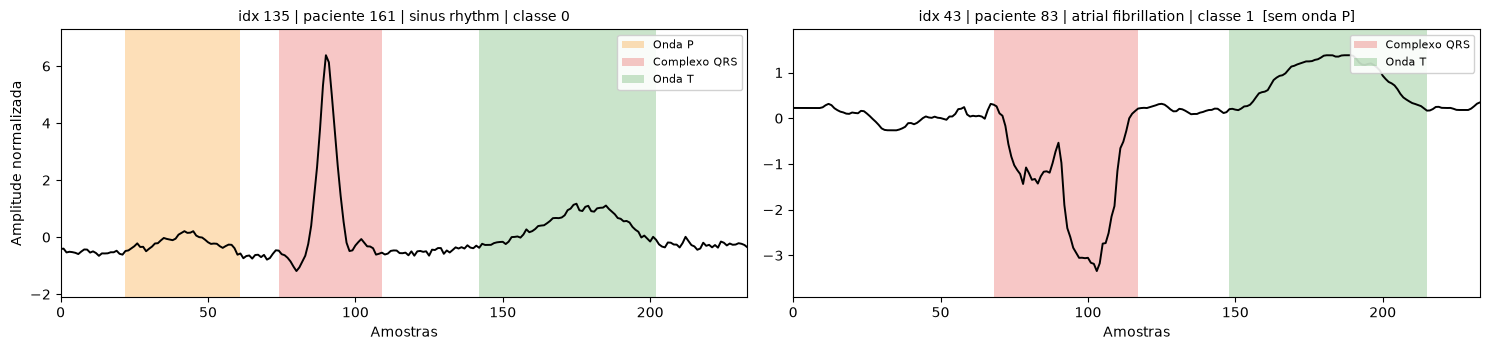

--- Batimento índice 135 ---
  paciente (registro)  : 161
  símbolo (ritmo)      : sinus rhythm
  classe binária       : 0 (referência negativa)
  pico R no sinal      : 2006
  tem onda P           : True
  região Onda P       : [ 22,  61] (40 amostras, 111 ms)
  região Complexo QRS : [ 74, 109] (36 amostras, 100 ms)
  região Onda T       : [142, 202] (61 amostras, 169 ms)
  cobertura P+QRS+T    : 58.5%

--- Batimento índice 43 ---
  paciente (registro)  : 83
  símbolo (ritmo)      : atrial fibrillation
  classe binária       : 1 (alvo compartilhado)
  pico R no sinal      : 2975
  tem onda P           : False
  região Onda P       : ausente neste ritmo
  região Complexo QRS : [ 68, 117] (50 amostras, 139 ms)
  região Onda T       : [148, 215] (68 amostras, 189 ms)
  cobertura P+QRS+T    : 50.4%



In [4]:
rng = np.random.default_rng(1)

idx_normal = rng.choice(np.flatnonzero(y == 0))
idx_arritmico = rng.choice(np.flatnonzero(y == 1))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
plot_batimento(idx_normal, axes[0])
plot_batimento(idx_arritmico, axes[1])
axes[0].set_ylabel("Amplitude normalizada")
for ax in axes:
    ax.set_xlabel("Amostras")
fig.tight_layout()
plt.show()

descrever_batimento(idx_normal)
descrever_batimento(idx_arritmico)

## 4. Um exemplo de cada ritmo

Nos ritmos de fibrilação e flutter atrial a faixa laranja da onda P não aparece:
a onda P não existe nesses ritmos, e é por isso que o critério de inclusão a
exige apenas dos registros que a possuem.

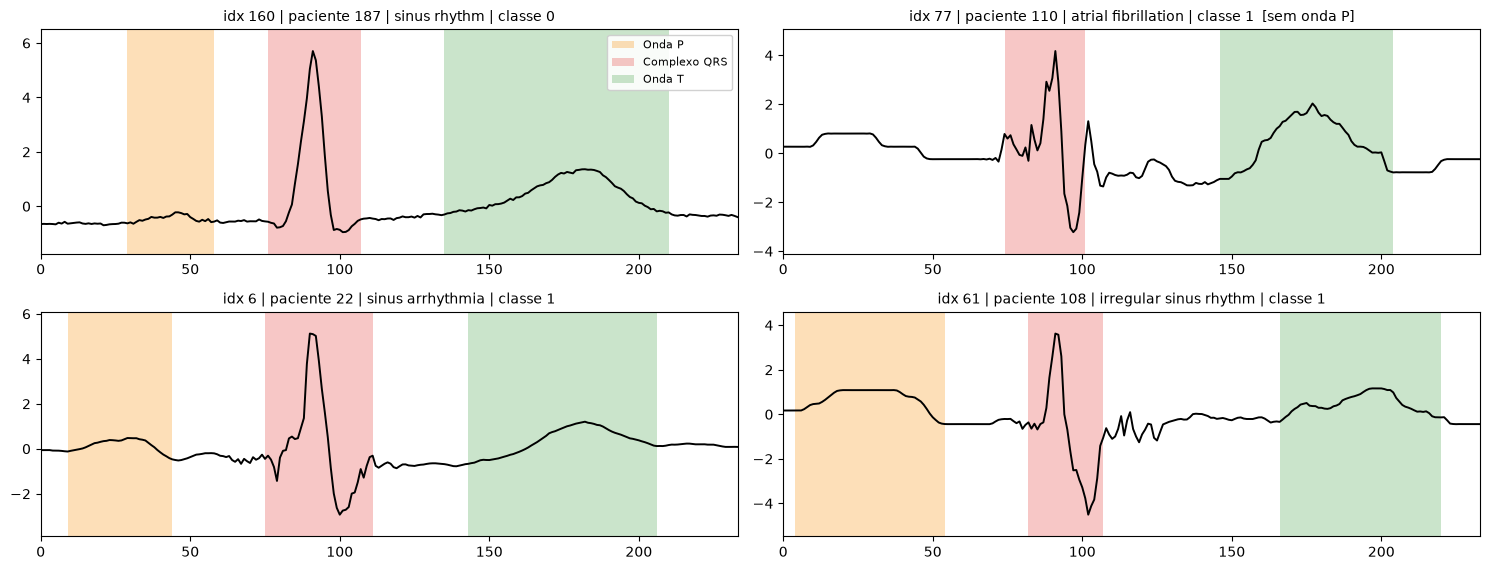

In [5]:
ritmos_ordenados = ritmos[ordem]
n_ritmos = len(ritmos_ordenados)
n_colunas = 2
n_linhas = int(np.ceil(n_ritmos / n_colunas))

fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(15, 2.9 * n_linhas))
axes = np.atleast_1d(axes).ravel()

for ax, ritmo in zip(axes, ritmos_ordenados):
    candidatos = np.flatnonzero(simbolos == ritmo)
    plot_batimento(rng.choice(candidatos), ax, legenda=False)

for ax in axes[n_ritmos:]:
    ax.axis("off")

axes[0].legend(fontsize=8, loc="upper right", framealpha=0.9)
fig.tight_layout()
plt.show()

## 5. Sobreposição de batimentos por classe

Confirma o alinhamento da segmentação: o pico R deve coincidir em todos os
batimentos, na amostra 90.

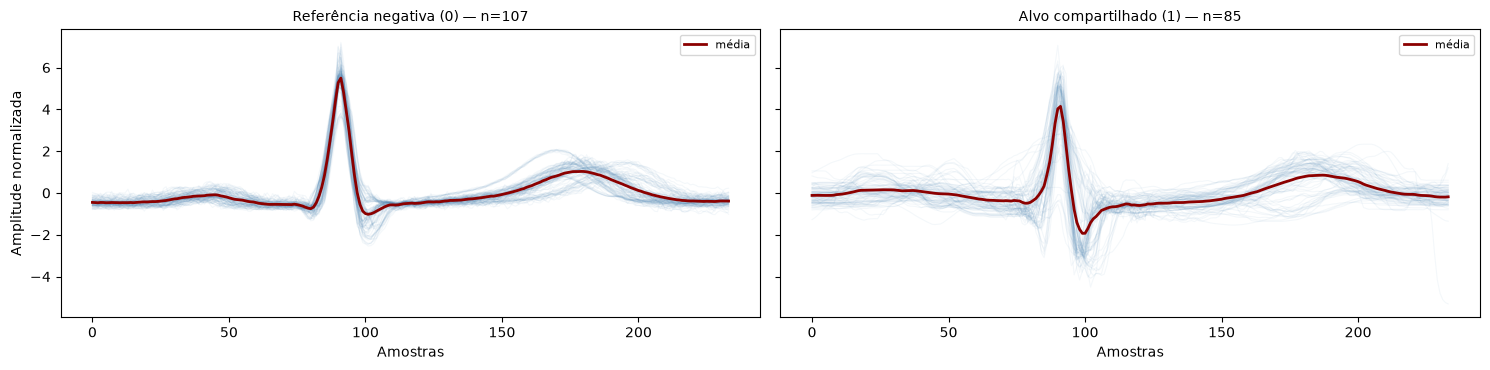

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)

for ax, classe, titulo in zip(axes, [0, 1], ["Referência negativa (0)", "Alvo compartilhado (1)"]):
    amostras = X[y == classe][:200]
    ax.plot(amostras.T, color="steelblue", alpha=0.06, linewidth=0.8)
    ax.plot(amostras.mean(axis=0), color="darkred", linewidth=2, label="média")
    ax.set_title(f"{titulo} — n={int((y == classe).sum())}", fontsize=10)
    ax.set_xlabel("Amostras")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Amplitude normalizada")
fig.tight_layout()
plt.show()